# DAY4 과제 02 : Iris 실전

데이터 파일 : `iris.csv` (붓꽃 150송이, 품종별 50송이)
출처 : UCI Machine Learning Repository - [Iris](https://archive.ics.uci.edu/dataset/53/iris)

세 붓꽃 품종의 꽃받침 길이 평균이 같은지 검정한다. 원본 150송이에서 품종별 30송이씩 직접 뽑아 표본 90송이로 분석한다.


- 유의수준은 α = 0.05 로 한다
- 결론은 두 줄로 쓴다 — 통계적 결론과 사실적 결론
- 조건 확인 결과를 보고 검정 방법을 직접 고른다

| 컬럼 | 설명 |
|---|---|
| sepal_length_cm | 꽃받침 길이 (cm) — **이번 과제에서 비교할 값** |
| sepal_width_cm | 꽃받침 너비 (cm) |
| petal_length_cm | 꽃잎 길이 (cm) |
| petal_width_cm | 꽃잎 너비 (cm) |
| species | 품종 (setosa / versicolor / virginica) — **집단을 나누는 기준** |

In [ ]:
%pip install -q koreanize-matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from scipy import stats

In [ ]:
import os

from google.colab import drive

drive.mount("/content/drive")
data_folder = "/content/drive/MyDrive/HD-AI/data"
csv_path = os.path.join(data_folder, "iris.csv")

df = pd.read_csv(csv_path)

data = df.copy()

### 1. 원본 데이터의 행 · 열 수와 품종별 송이 수를 확인하시오.

In [ ]:
print("행·열:", data.shape)
data["species"].value_counts()

행·열: (150, 5)


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

### 2. 품종마다 30송이씩 무작위로 뽑아 하나의 표 `sample_df` 로 합치시오. (`random_state=42`) 표본의 품종별 송이 수를 확인하시오.

In [ ]:
sample_df = pd.concat([data.loc[data["species"] == "setosa"].sample(n=30, random_state=42),
                       data.loc[data["species"] == "versicolor"].sample(n=30, random_state=42),
                       data.loc[data["species"] == "virginica"].sample(n=30, random_state=42)])
#   품종마다 먼저 행을 고른 뒤 sample(n=30) 으로 30송이를 뽑는다. 기본값 replace=False 라 같은 송이를 두 번 뽑지 않는다
#   random_state=42 : 실행할 때마다 같은 30송이가 뽑히도록 고정한다
#   pd.concat([표1, 표2, 표3]) : 세 표를 위아래로 이어 붙인다 → 90행
print("표본 행·열:", sample_df.shape)
sample_df["species"].value_counts()

표본 행·열: (90, 5)


species
setosa        30
versicolor    30
virginica     30
Name: count, dtype: int64

### 3. 표본에서 품종별 꽃받침 길이의 송이 수 · 평균 · 표준편차를 한 표로 구하시오. (소수 셋째 자리까지)

In [ ]:
sample_df.groupby("species")["sepal_length_cm"].agg(["count", "mean", "std"]).round(3)

,count,mean,std
species,,,
setosa,30,4.987,0.333
versicolor,30,5.983,0.513
virginica,30,6.583,0.613


### 4. 품종별 꽃받침 길이를 `setosa`, `versicolor`, `virginica` 세 변수로 꺼내고, 히스토그램을 1행 3열로 그리시오.

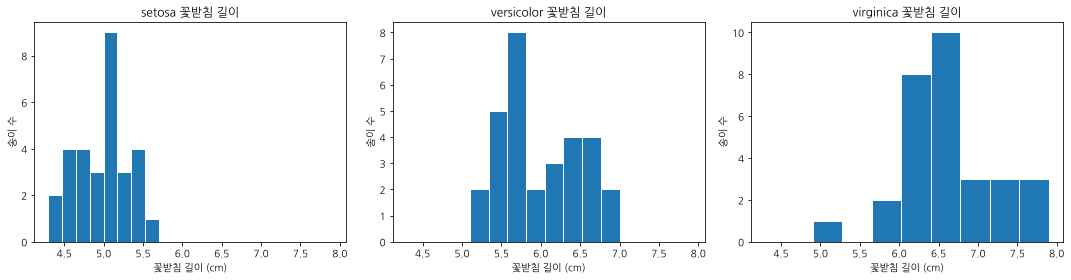

In [ ]:
setosa = sample_df.loc[sample_df["species"] == "setosa", "sepal_length_cm"]
versicolor = sample_df.loc[sample_df["species"] == "versicolor", "sepal_length_cm"]
virginica = sample_df.loc[sample_df["species"] == "virginica", "sepal_length_cm"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)   # sharex=True : 세 그래프의 가로축 범위를 같게
for ax, values, title in zip(axes, [setosa, versicolor, virginica], ["setosa", "versicolor", "virginica"]):
    ax.hist(values, bins=8, edgecolor="white")
    ax.set(title=title + " 꽃받침 길이", xlabel="꽃받침 길이 (cm)", ylabel="송이 수")
plt.tight_layout()
plt.show()

### 5. 품종마다 Shapiro-Wilk 정규성 검정의 p값을 구하고, Levene 검정으로 세 품종의 분산이 같은지 확인하시오.

- 귀무가설(H₀): 이 품종의 꽃받침 길이는 정규분포를 따른다. / 대립가설(H₁): 정규분포를 따르지 않는다.
- 귀무가설(H₀): 세 품종 꽃받침 길이의 모분산은 같다. (σ₁² = σ₂² = σ₃²) / 대립가설(H₁): 적어도 한 품종의 모분산이 다르다.

In [ ]:
print("Shapiro p setosa:", round(stats.shapiro(setosa).pvalue, 3))
print("Shapiro p versicolor:", round(stats.shapiro(versicolor).pvalue, 3))
print("Shapiro p virginica:", round(stats.shapiro(virginica).pvalue, 3))
print("Levene p:", round(stats.levene(setosa, versicolor, virginica).pvalue, 3))

Shapiro p setosa: 0.882
Shapiro p versicolor: 0.247
Shapiro p virginica: 0.208
Levene p: 0.041


### 6. 5번 결과에 맞는 방법으로 세 품종의 평균 꽃받침 길이가 같은지 검정하시오.

- 귀무가설(H₀): 세 품종의 모평균 꽃받침 길이는 같다. (μ_setosa = μ_versicolor = μ_virginica)
- 대립가설(H₁): 적어도 한 품종의 모평균 꽃받침 길이가 다르다. (적어도 한 μ가 다르다)

| 5번 결과 | 검정 |
|---|---|
| 정규성 O · 등분산 O | 일원분산분석 `stats.f_oneway(a, b, c)` |
| 정규성 O · 등분산 X | Welch ANOVA `stats.f_oneway(a, b, c, equal_var=False)` |
| 정규성이 크게 어긋남 | Kruskal-Wallis `stats.kruskal(a, b, c)` |

In [ ]:
welch = stats.f_oneway(setosa, versicolor, virginica, equal_var=False)
#   Levene p = 0.041 < 0.05 → 분산이 같다고 보기 어렵다 → 등분산을 가정하지 않는 Welch ANOVA
#   equal_var=False : "분산이 같다고 가정하지 않는다" (SciPy 1.16.0 이상)
print("Welch F:", round(welch.statistic, 2))
print("p값:", welch.pvalue)                     # p값이 매우 작아 지수 표기로 나온다

Welch F: 94.65
p값: 2.1474884147000514e-18


### 7. 6번에서 귀무가설을 기각했다면, 등분산을 가정하지 않는 사후검정(Games-Howell)으로 어느 품종끼리 다른지 확인하시오.

쌍마다
- 귀무가설(H₀): 두 품종의 모평균 꽃받침 길이는 같다. (예 : μ_setosa = μ_versicolor)
- 대립가설(H₁): 두 품종의 모평균 꽃받침 길이는 다르다. (예 : μ_setosa ≠ μ_versicolor)

In [ ]:
games = stats.tukey_hsd(setosa, versicolor, virginica, equal_var=False)   # 0 = setosa, 1 = versicolor, 2 = virginica
print(games)                                       # Statistic = 앞 품종 평균 − 뒤 품종 평균
print("setosa − versicolor 조정 p값:", games.pvalue[0, 1])
print("setosa − virginica 조정 p값:", games.pvalue[0, 2])     # 0 으로 나오면 아주 작아서 0 에 가깝다는 뜻이다
print("versicolor − virginica 조정 p값:", round(games.pvalue[1, 2], 4))

Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)     -0.997     0.000    -1.266    -0.727
 (0 - 2)     -1.597     0.000    -1.905    -1.288
 (1 - 0)      0.997     0.000     0.727     1.266
 (1 - 2)     -0.600     0.000    -0.951    -0.249
 (2 - 0)      1.597     0.000     1.288     1.905
 (2 - 1)      0.600     0.000     0.249     0.951

setosa − versicolor 조정 p값: 1.9545698393130806e-11
setosa − virginica 조정 p값: 0.0
versicolor − virginica 조정 p값: 0.0004
